# Paper figure: cross-app nearest neighbors

This qualitative retrieval figure uses representative ENRICO queries and searches the complete local RICO embedding collection. Candidates from the query app are excluded, so visual or structural matches cannot be explained by app identity. Similarities are exact cosine similarities between normalized `embeddings_4096_last` vectors—no UMAP distances are used.

In [1]:
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm.auto import tqdm

from paper_embedding_analysis import (LAYOUTS_DIR, PROJECT_ROOT, available_embedding_ids, load_embedding_file, load_embeddings, output_dir, package_from_layout, read_enrico_topics)

sns.set_theme(context="paper", style="white", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 300})

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
EMBEDDINGS_DIR = PROJECT_ROOT / "embeddings_4096_last"
QUERY_TOPICS = ("login", "list", "settings", "profile")
TOP_K = 3
BATCH_SIZE = 512
WORKERS = 12
METRIC_EXCLUDED_TOPICS = {"other"}
BOOTSTRAP_SAMPLES = 5_000
OUTPUT_DIR = output_dir(f"overleaf/graphics")

if not EMBEDDINGS_DIR.is_dir():
    raise FileNotFoundError(f"Embedding directory does not exist: {EMBEDDINGS_DIR}")

## Choose reproducible representative queries

By default, each requested ENRICO topic uses its medoid: the screen with the highest mean cosine similarity to the other matched screens in that topic. For the qualitative figure, `QUERY_SCREEN_OVERRIDES` can replace individual medoids with clearer examples. The override must be an available RICO screen carrying the same ENRICO topic label.

To change a query image, edit the RICO id below, then rerun the override cell and every code cell below it (or use **Restart Kernel and Run All Cells**). Remove a topic from the dictionary—or set it to `None`—to restore automatic medoid selection. The quantitative mAP cell is unaffected because it always evaluates every eligible query.

In [3]:
# Optional RICO screen ids for the qualitative figure.
# Remove an entry, or set it to None, to use that topic's automatic medoid.
QUERY_SCREEN_OVERRIDES = {
    "login": 50769,    # clear sign-up form; avoids the weak green Kiwi match
    "settings": 61678, # produces a more varied set of settings neighbors
}

In [4]:
topics = read_enrico_topics()
available = available_embedding_ids(EMBEDDINGS_DIR)
pool = topics[topics["screen_id"].isin(available) & topics["topic"].isin(QUERY_TOPICS)].copy()
ids, topic_vectors = load_embeddings(pool["screen_id"], EMBEDDINGS_DIR, description="Loading ENRICO query pool")
id_to_vector = dict(zip(ids, topic_vectors))
query_rows = []
for topic in QUERY_TOPICS:
    topic_ids = pool.loc[pool["topic"] == topic, "screen_id"].tolist()
    override = QUERY_SCREEN_OVERRIDES.get(topic)
    if override is None:
        matrix = np.stack([id_to_vector[screen_id] for screen_id in topic_ids])
        medoid_index = int(np.argmax((matrix @ matrix.T).mean(axis=1)))
        screen_id = topic_ids[medoid_index]
        selection = "medoid"
    else:
        screen_id = int(override)
        if screen_id not in topic_ids:
            raise ValueError(
                f"Override {screen_id} is not an available ENRICO '{topic}' screen"
            )
        selection = "override"
    package = package_from_layout(LAYOUTS_DIR / f"{screen_id}.json")
    query_rows.append({"topic": topic, "screen_id": screen_id, "selection": selection, "package": package, "embedding": id_to_vector[screen_id]})
queries = pd.DataFrame(query_rows)
query_matrix = np.stack(queries["embedding"])
display(queries.drop(columns="embedding"))

Loading ENRICO query pool:   0%|          | 0/518 [00:00<?, ?it/s]

Loading ENRICO query pool:  29%|██▉       | 152/518 [00:00<00:00, 1519.84it/s]

Loading ENRICO query pool:  59%|█████▊    | 304/518 [00:00<00:00, 1406.80it/s]

Loading ENRICO query pool:  86%|████████▌ | 446/518 [00:00<00:00, 1338.08it/s]

Loading ENRICO query pool: 100%|██████████| 518/518 [00:00<00:00, 1372.72it/s]

,topic,screen_id,selection,package
0,login,50769,override,com.skillshare.Skillshare
1,list,67717,medoid,com.app.istirja3krtot
2,settings,61678,override,com.ghostwording.stickerbliss
3,profile,53944,medoid,com.narvii.amino.x89


## Exact cross-app search

The scan is batched to keep memory bounded. It reads every genuine one-token last-token embedding and retains only the best candidates from a different package.

In [5]:
candidate_paths = sorted(EMBEDDINGS_DIR.glob("*.npz"), key=lambda p: int(p.stem))
best = {i: [] for i in range(len(queries))}

def load_candidate(path):
    screen_id = int(path.stem)
    package = package_from_layout(LAYOUTS_DIR / f"{screen_id}.json")
    return screen_id, package, load_embedding_file(path)

with ThreadPoolExecutor(max_workers=WORKERS) as executor:
    for start in tqdm(range(0, len(candidate_paths), BATCH_SIZE), desc="Searching all RICO screens"):
        records = list(executor.map(load_candidate, candidate_paths[start:start + BATCH_SIZE]))
        batch_ids = np.array([record[0] for record in records])
        batch_packages = [record[1] for record in records]
        batch_matrix = np.stack([record[2] for record in records])
        similarities = batch_matrix @ query_matrix.T
        for query_index, query in queries.iterrows():
            valid = [i for i, package in enumerate(batch_packages) if batch_ids[i] != query.screen_id and package != query.package]
            local = sorted(valid, key=lambda i: similarities[i, query_index], reverse=True)[:TOP_K]
            best[query_index].extend((float(similarities[i, query_index]), int(batch_ids[i]), batch_packages[i]) for i in local)
            best[query_index] = sorted(best[query_index], reverse=True)[:TOP_K]

topic_lookup = topics.set_index("screen_id")["topic"].to_dict()
result_rows = []
for query_index, query in queries.iterrows():
    for rank, (similarity, screen_id, package) in enumerate(best[query_index], start=1):
        result_rows.append({"query_topic": query.topic, "query_id": query.screen_id, "query_package": query.package, "rank": rank, "neighbor_id": screen_id, "neighbor_package": package, "neighbor_enrico_topic": topic_lookup.get(screen_id), "cosine_similarity": similarity})
results = pd.DataFrame(result_rows)
display(results.style.format({"cosine_similarity": "{:.4f}"}))
results.to_csv(OUTPUT_DIR / "cross_app_nearest_neighbors.csv", index=False)

Searching all RICO screens:   0%|          | 0/130 [00:00<?, ?it/s]

Searching all RICO screens:   1%|          | 1/130 [00:00<02:06,  1.02it/s]

Searching all RICO screens:   2%|▏         | 2/130 [00:01<01:59,  1.07it/s]

Searching all RICO screens:   2%|▏         | 3/130 [00:02<01:59,  1.06it/s]

Searching all RICO screens:   3%|▎         | 4/130 [00:04<02:22,  1.13s/it]

Searching all RICO screens:   4%|▍         | 5/130 [00:05<02:14,  1.08s/it]

... (123 outputs left out)

Searching all RICO screens:  99%|█████████▉| 129/130 [01:57<00:00,  1.62it/s]

Searching all RICO screens: 100%|██████████| 130/130 [01:57<00:00,  1.97it/s]

Searching all RICO screens: 100%|██████████| 130/130 [01:57<00:00,  1.10it/s]

,query_topic,query_id,query_package,rank,neighbor_id,neighbor_package,neighbor_enrico_topic,cosine_similarity
0,login,50769,com.skillshare.Skillshare,1,48791,com.udacity.android,None,0.7832
1,login,50769,com.skillshare.Skillshare,2,26267,com.reverllc.rever,None,0.7640
2,login,50769,com.skillshare.Skillshare,3,36427,com.weheartit,None,0.7582
3,list,67717,com.app.istirja3krtot,1,50418,com.IQBS.android.app2sd,None,0.6960
4,list,67717,com.app.istirja3krtot,2,50416,com.IQBS.android.app2sd,None,0.6895
5,list,67717,com.app.istirja3krtot,3,62573,com.antivirus,None,0.6862
6,settings,61678,com.ghostwording.stickerbliss,1,46209,com.ghostwording.stickers,None,0.7956
7,settings,61678,com.ghostwording.stickerbliss,2,4702,com.shareitagain.mymoodsmiley,None,0.6914
8,settings,61678,com.ghostwording.stickerbliss,3,41729,com.funeasylearn.italian,None,0.6797
9,profile,53944,com.narvii.amino.x89,1,52924,com.narvii.amino.x172349881,None,0.8904


## Quantitative summary: macro cross-app Top-k accuracy and MRR

Every usable ENRICO screen is a query; the gallery contains only ENRICO-labeled screens from other apps, and a result is relevant when it has the same ENRICO topic. A query is correct at a cutoff when at least one relevant screen occurs within that part of its ranked gallery. We report Top-1, Top-0.01%, Top-0.1%, Top-1%, and Top-5% accuracy, together with mean reciprocal rank (MRR). Percentage cutoffs use `max(1, ceil(percentage * gallery_size))`, matching the repository's permissive retrieval convention.

We first average each query-level metric within its topic and then give every topic equal weight, preventing frequent topics such as `list` from dominating. The heterogeneous ENRICO rejection class `other` is excluded by default. The full-RICO figure above remains qualitative because most RICO screens have no topic label and therefore cannot be scored as relevant or irrelevant. The quantitative evaluation uses the labeled subset, all eligible queries rather than medoids, and a topic-stratified, app-cluster bootstrap 95% confidence interval.

In [6]:
evaluation = topics[
    topics["screen_id"].isin(available)
    & ~topics["topic"].isin(METRIC_EXCLUDED_TOPICS)
].copy()
evaluation["package"] = [
    package_from_layout(LAYOUTS_DIR / f"{screen_id}.json")
    for screen_id in evaluation["screen_id"]
]
evaluation = evaluation.dropna(subset=["package"])
eval_ids, eval_matrix = load_embeddings(
    evaluation["screen_id"],
    EMBEDDINGS_DIR,
    workers=WORKERS,
    description="Loading ENRICO metric pool",
)
evaluation = evaluation.set_index("screen_id").loc[eval_ids].reset_index()
eval_ids_array = evaluation["screen_id"].to_numpy(dtype=np.int64)
eval_topics = evaluation["topic"].to_numpy(dtype=str)
eval_packages = evaluation["package"].to_numpy(dtype=object)
eval_similarities = eval_matrix @ eval_matrix.T

percentage_cutoffs = {
    "top_0_01pct_accuracy": 0.0001,
    "top_0_1pct_accuracy": 0.001,
    "top_1pct_accuracy": 0.01,
    "top_5pct_accuracy": 0.05,
}
metric_rows = []
for query_index, query in evaluation.iterrows():
    valid = (eval_ids_array != query.screen_id) & (eval_packages != query.package)
    gallery_size = int(valid.sum())
    order = np.argsort(-eval_similarities[query_index, valid], kind="stable")
    ranked_relevant = eval_topics[valid][order] == query.topic
    relevant_count = int(ranked_relevant.sum())
    if relevant_count == 0:
        continue
    relevant_ranks = np.flatnonzero(ranked_relevant) + 1
    first_relevant_rank = int(relevant_ranks[0])
    percentage_hits = {
        metric: float(first_relevant_rank <= max(1, int(np.ceil(fraction * gallery_size))))
        for metric, fraction in percentage_cutoffs.items()
    }
    metric_rows.append(
        {
            "screen_id": int(query.screen_id),
            "topic": query.topic,
            "package": query.package,
            "gallery_size": gallery_size,
            "relevant_count": relevant_count,
            "top_1_accuracy": float(first_relevant_rank == 1),
            **percentage_hits,
            "reciprocal_rank": float(1.0 / first_relevant_rank),
        }
    )

per_query_metrics = pd.DataFrame(metric_rows)
per_topic_metrics = (
    per_query_metrics.groupby("topic", sort=True)
    .agg(
        n_queries=("screen_id", "size"),
        top_1_accuracy=("top_1_accuracy", "mean"),
        top_0_01pct_accuracy=("top_0_01pct_accuracy", "mean"),
        top_0_1pct_accuracy=("top_0_1pct_accuracy", "mean"),
        top_1pct_accuracy=("top_1pct_accuracy", "mean"),
        top_5pct_accuracy=("top_5pct_accuracy", "mean"),
        mean_reciprocal_rank=("reciprocal_rank", "mean"),
    )
    .reset_index()
)
metric_columns = [
    "top_1_accuracy",
    "top_0_01pct_accuracy",
    "top_0_1pct_accuracy",
    "top_1pct_accuracy",
    "top_5pct_accuracy",
    "mean_reciprocal_rank",
]
macro_values = per_topic_metrics[metric_columns].mean()

rng = np.random.default_rng(42)
query_metric_columns = metric_columns[:-1] + ["reciprocal_rank"]
topic_package_metrics = [
    [package_group[query_metric_columns].to_numpy(dtype=np.float64) for _, package_group in topic_group.groupby("package")]
    for _, topic_group in per_query_metrics.groupby("topic")
]
bootstrap_macro = np.empty((BOOTSTRAP_SAMPLES, len(metric_columns)), dtype=np.float64)
for sample_index in range(BOOTSTRAP_SAMPLES):
    topic_means = []
    for package_values in topic_package_metrics:
        sampled_packages = rng.integers(len(package_values), size=len(package_values))
        sampled_values = np.concatenate([package_values[index] for index in sampled_packages], axis=0)
        topic_means.append(sampled_values.mean(axis=0))
    bootstrap_macro[sample_index] = np.mean(topic_means, axis=0)
ci_low, ci_high = np.quantile(bootstrap_macro, [0.025, 0.975], axis=0)

metric_summary = pd.DataFrame(
    [
        {
            "embeddings": EMBEDDINGS_DIR.name,
            "metric": f"macro_{metric}",
            "value": float(macro_values[metric]),
            "ci95_low": float(ci_low[index]),
            "ci95_high": float(ci_high[index]),
            "n_queries": len(per_query_metrics),
            "n_topics": len(per_topic_metrics),
        }
        for index, metric in enumerate(metric_columns)
    ]
)
display_names = {
    "top_1_accuracy": "Top-1",
    "top_0_01pct_accuracy": "Top-0.01%",
    "top_0_1pct_accuracy": "Top-0.1%",
    "top_1pct_accuracy": "Top-1%",
    "top_5pct_accuracy": "Top-5%",
    "mean_reciprocal_rank": "MRR",
}
per_topic_display = per_topic_metrics.rename(columns=display_names)
display(metric_summary.style.format({"value": "{:.4f}", "ci95_low": "{:.4f}", "ci95_high": "{:.4f}"}, na_rep="—"))
display(per_topic_display.style.format({name: "{:.4f}" for name in display_names.values()}))
per_query_metrics.to_csv(OUTPUT_DIR / "cross_app_topic_metrics_per_query.csv", index=False)
per_topic_metrics.to_csv(OUTPUT_DIR / "cross_app_topic_metrics_per_topic.csv", index=False)
metric_summary.to_csv(OUTPUT_DIR / "cross_app_topic_metric_summary.csv", index=False)

Loading ENRICO metric pool:   0%|          | 0/1300 [00:00<?, ?it/s]

Loading ENRICO metric pool:  12%|█▏        | 161/1300 [00:00<00:00, 1555.74it/s]

Loading ENRICO metric pool:  24%|██▍       | 317/1300 [00:00<00:00, 1461.11it/s]

Loading ENRICO metric pool:  36%|███▌      | 464/1300 [00:00<00:00, 1392.47it/s]

Loading ENRICO metric pool:  46%|████▋     | 604/1300 [00:00<00:00, 1366.57it/s]

Loading ENRICO metric pool:  57%|█████▋    | 741/1300 [00:00<00:00, 1333.32it/s]

... (3 outputs left out)

Loading ENRICO metric pool:  97%|█████████▋| 1257/1300 [00:00<00:00, 1239.81it/s]

Loading ENRICO metric pool: 100%|██████████| 1300/1300 [00:00<00:00, 1306.32it/s]

,embeddings,metric,value,ci95_low,ci95_high,n_queries,n_topics
0,embeddings_4096_last,macro_top_1_accuracy,0.2932,0.2592,0.3311,1300,19
1,embeddings_4096_last,macro_top_0_01pct_accuracy,0.2932,0.2592,0.3311,1300,19
2,embeddings_4096_last,macro_top_0_1pct_accuracy,0.4166,0.3775,0.4579,1300,19
3,embeddings_4096_last,macro_top_1pct_accuracy,0.7777,0.7234,0.8159,1300,19
4,embeddings_4096_last,macro_top_5pct_accuracy,0.9341,0.8846,0.9628,1300,19
5,embeddings_4096_last,macro_mean_reciprocal_rank,0.4359,0.4022,0.4697,1300,19


,topic,n_queries,Top-1,Top-0.01%,Top-0.1%,Top-1%,Top-5%,MRR
0,bare,71,0.2254,0.2254,0.3239,0.7042,0.9577,0.3629
1,calculator,5,0.2000,0.2000,0.4000,0.6000,0.8000,0.3478
2,camera,8,0.0000,0.0000,0.0000,0.8750,0.8750,0.2312
3,chat,11,0.2727,0.2727,0.2727,0.8182,0.9091,0.3587
4,editor,18,0.5000,0.5000,0.5556,0.7222,0.8889,0.5629
5,form,95,0.4105,0.4105,0.5684,0.9158,0.9789,0.5719
6,gallery,131,0.3740,0.3740,0.5573,0.9389,1.0000,0.5511
7,list,249,0.4337,0.4337,0.6265,0.9880,1.0000,0.6127
8,login,127,0.6142,0.6142,0.7953,0.9291,0.9764,0.7404
9,maps,9,0.2222,0.2222,0.2222,0.4444,0.7778,0.2831


C:\Users\Jonathan\Dev\screen2vec-revisited\graphics\overleaf\graphics\cross_app_nearest_neighbors.pdf


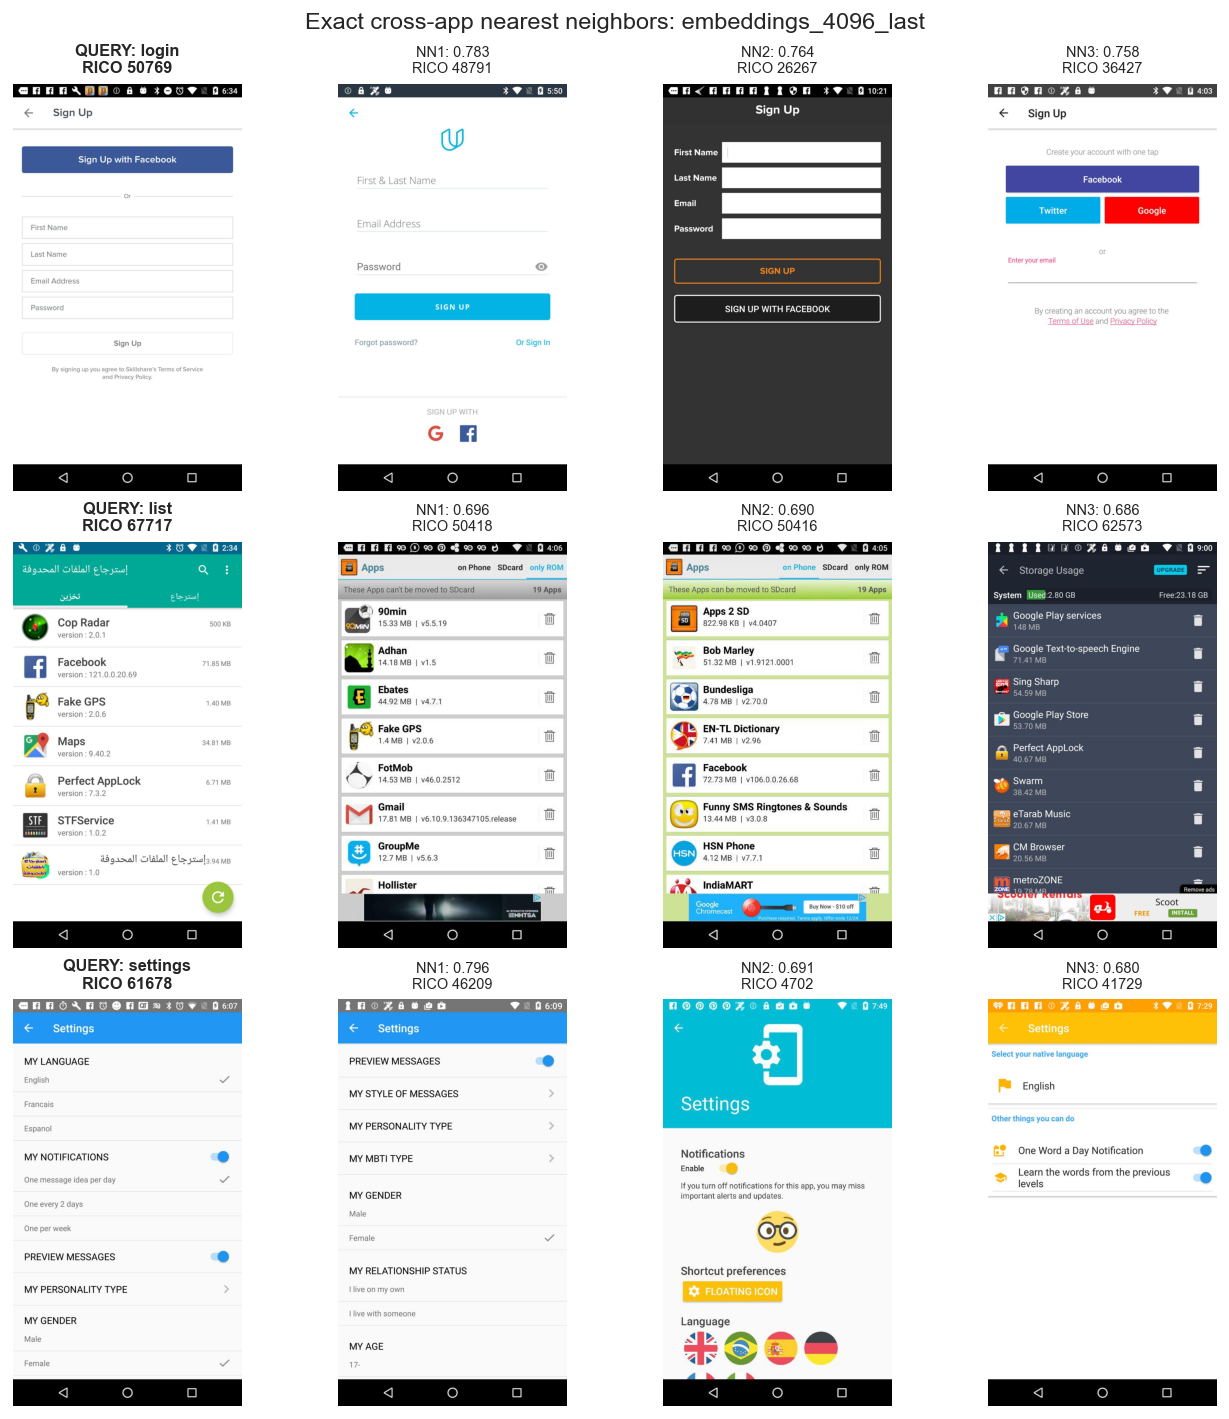

In [7]:
figure_queries = queries[queries["topic"].isin(("login", "list", "settings"))].reset_index(drop=True)
fig, axes = plt.subplots(len(figure_queries), TOP_K + 1, figsize=(10, 3.6 * len(figure_queries)), constrained_layout=True)
for row_index, query in figure_queries.iterrows():
    query_image = plt.imread(LAYOUTS_DIR / f"{query.screen_id}.jpg")
    axes[row_index, 0].imshow(query_image)
    axes[row_index, 0].set_title(f"QUERY: {query.topic}\nRICO {query.screen_id}", fontsize=9, weight="bold")
    query_results = results[results["query_id"] == query.screen_id].sort_values("rank")
    for column, neighbor in enumerate(query_results.itertuples(), start=1):
        neighbor_image = plt.imread(LAYOUTS_DIR / f"{neighbor.neighbor_id}.jpg")
        axes[row_index, column].imshow(neighbor_image)
        axes[row_index, column].set_title(f"NN{neighbor.rank}: {neighbor.cosine_similarity:.3f}\nRICO {neighbor.neighbor_id}", fontsize=8)
    for ax in axes[row_index]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
fig.suptitle(f"Exact cross-app nearest neighbors: {EMBEDDINGS_DIR.name}", fontsize=13)
fig.savefig(OUTPUT_DIR / "cross_app_nearest_neighbors.png", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "cross_app_nearest_neighbors.pdf", bbox_inches="tight")
print(OUTPUT_DIR / "cross_app_nearest_neighbors.pdf")
plt.show()